<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">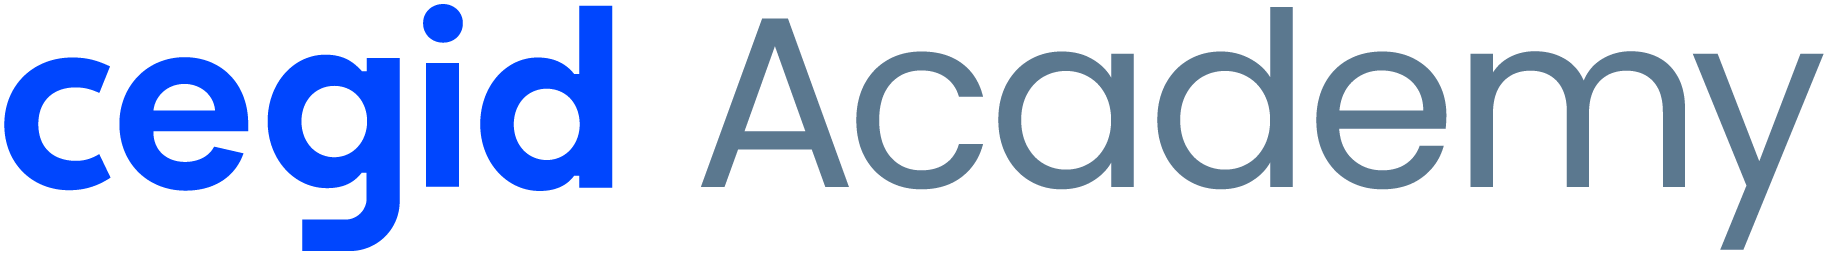<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 3 &middot; Preparação dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Preparation</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M3.01 · M3.02</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Transformar dados brutos em dados <b>modeláveis</b>: garantir qualidade, reduzir ruído e evitar enviesamentos. É tipicamente a fase que consome <b>60–80% do tempo</b> do projeto. Todas as decisões devem vir da síntese da Fase 2.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage</div><b>Regra de ouro contra o <i>data leakage</i>:</b> qualquer transformação que <b>aprende parâmetros</b> dos dados (média/mediana da imputação, categorias do encoding, média e desvio do scaling, componentes do PCA, limites de outliers, target encoding) deve ser ajustada <b>apenas no conjunto de treino</b> e depois aplicada ao teste. Por isso, a divisão treino/teste é feita <b>antes</b> dessas transformações.</div>

**Ordem recomendada (M3)**

1. Seleção de dados → 2. Limpeza determinística → 3. **Separação treino/teste** → 4. Feature engineering → 5. Valores em falta → 6. Outliers → 7. Encoding → 8. Scaling → 9. Redução de dimensionalidade → 10. Pipeline final → 11. Exportação

### 0. Configuração
<hr>

Usar **a mesma configuração** do notebook 02.

**0.1 Bibliotecas**
- `numpy`, `pandas`, `matplotlib`, `seaborn`, `json`, `pathlib`.
- Do scikit-learn: `train_test_split`, encoders (`OneHotEncoder`, `LabelEncoder`, `OrdinalEncoder`), scalers, imputers (`SimpleImputer`, `KNNImputer`), seleção (`VarianceThreshold`, `SelectKBest`, `RFE`), `PCA`, `Pipeline` e `ColumnTransformer`.

**0.2 Configuração do projeto** — os **mesmos** valores do notebook 02 (`PROJETO`, `DATA_PATH`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `RANDOM_STATE`, `TEST_SIZE`).

**0.3 Estrutura de pastas** — igual ao notebook 02 (`Data/input`, `Data/output`, `Data/analytics`, `Data/models`).

**0.4 Carregar os dados**
- Ler o dataset original para `df_raw` e trabalhar numa cópia `df` (o original nunca é alterado).

### 1. Seleção de dados
<hr>

**Descrever que dados serão utilizados no modelo:**

- Que variáveis serão consideradas? Quais serão removidas e porquê?
- Colunas irrelevantes (identificadores, texto livre sem valor, colunas constantes)?
- Variáveis redundantes (a mesma informação noutra forma, ex.: `Attrition` e `AttritionFlag`)?
- Variáveis que **revelam o target** ou que não existiriam no momento da previsão (*leakage*)?
- O dataset será filtrado (por país, período, categoria)?

***Objetivo:*** definir claramente o subconjunto de dados a utilizar.

**1.1 Seleção de dados**
- Remover as colunas irrelevantes, redundantes ou que revelam o alvo (decididas na Fase 2) — `drop(columns=...)`.
- Aplicar filtros de linhas, se fizer sentido.
- Os identificadores (`ID_COLS`) podem ficar no DataFrame para rastreabilidade, mas não vão entrar no modelo.

##### Análise e Interpretação

> *Que variáveis foram removidas e porquê?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Exemplo HR (regressão de <code>MonthlyIncome</code>): foram removidos <code>EmployeeID</code> (identificador), <code>Attrition</code> (redundante) e <code>AttritionFlag</code> (rótulo de saída que enviesaria a estimação salarial).</div>

### 2. Limpeza determinística (antes da divisão)
<hr>

Correções que **não aprendem nada com os dados** e podem ser feitas no dataset completo:

- **Duplicados**: remover os que são erros de registo
- **Tipos de dados**: converter texto para número/data, números para categoria
- **String processing**: remover espaços, uniformizar maiúsculas/minúsculas, corrigir categorias
- **Date/Time processing**: extrair ano, mês, dia da semana, fim de semana, diferenças entre datas
- **Códigos de missing disfarçados** (999, −1, `0` impossível) → `NaN` verdadeiro
- **Colunas redundantes**: a mesma informação noutra forma — e atenção a variáveis que são o **alvo disfarçado** (no Titanic, `alive`) → removê-las é prevenção de *leakage*
- **Inconsistências**: valores impossíveis (negativos, % > 100) → `NaN`
- **Target**: garantir que está codificado (ex.: `"Yes"/"No"` → `1/0`)

> **Determinística** = regra fixa definida por vocês (ex.: `999 → NaN`, `"hr " → "HR"`). Se a regra usa uma estatística dos dados (mediana, quantis, frequências, data mínima do dataset), deixa de ser determinística e passa para depois da divisão.

***Objetivo:*** garantir qualidade e coerência dos dados.

**2.1 Duplicados**
- Remover duplicados (`drop_duplicates`) e indicar quantos foram removidos.

##### Análise e Interpretação

> *Os duplicados eram erros? Quantos foram removidos?*

**Resposta:**

- 

<hr>

**2.2 String processing (M3.01)**
- Nas variáveis de texto: remover espaços (`str.strip`), espaços repetidos (`str.replace(r"\s+", " ", regex=True)`), uniformizar maiúsculas/minúsculas e corrigir categorias escritas de formas diferentes (`replace`).
- (Se aplicável) extrair informação com regex (`str.extract`).

##### Análise e Interpretação

> *Que correções de texto foram necessárias?*

**Resposta:**

- 

<hr>

**2.3 Tipos de dados e datas (M3.01)**
- Converter tipos errados (`pd.to_datetime`, `astype`).
- Se houver datas: criar ano, mês, dia da semana, fim de semana, dias desde uma data de referência **fixa** (ex.: a data de início do contrato — não a data mínima do dataset) (`.dt`).

##### Análise e Interpretação

> *Que conversões foram feitas? As novas variáveis temporais fazem sentido para o problema?*

**Resposta:**

- 

<hr>

**2.4 Códigos de missing e inconsistências (M3.01)**
- Converter códigos de missing disfarçados (999, −1, 0 impossível) e valores impossíveis em `np.nan`.

##### Análise e Interpretação

> *Que valores foram convertidos em nulos e porquê?*

**Resposta:**

- 

<hr>

**2.5 [Classificação] Codificar o alvo**
- Se o target estiver em texto, convertê-lo em números com `LabelEncoder` e mostrar o mapeamento (`classes_`).
- Garantir que a **classe de interesse** (a que se quer detetar: sair, fraude, doença…) fica codificada como `1`: precision, recall e F1 usam `pos_label=1` por omissão. O `LabelEncoder` ordena alfabeticamente — em binário, um `map` explícito (ex.: `{"No": 0, "Yes": 1}`) é mais seguro.

### 3. Separação dos dados (treino / teste)
<hr>

- Proporção: 80/20 ou 70/30 (compromisso entre dados para aprender e dados para validar)
- `random_state` → reprodutibilidade
- `stratify=y` em classificação → mantém a proporção das classes em treino e teste
- O **conjunto de teste fica "intocado"** até à avaliação do modelo final (Fase 4, secção 7, e Fase 5): não é usado para escolher variáveis, estratégias de preparação, modelos, hiperparâmetros ou limiares
- **Dados temporais** → divisão cronológica (dados ordenados por data e `shuffle=False`, ou corte por data) em vez de aleatória
- **Várias linhas por entidade** → divisão por grupo (`GroupShuffleSplit`), para a mesma entidade não ficar no treino e no teste
- A validação cruzada é feita na Fase 4, **apenas com o treino**

***Objetivo:*** garantir uma avaliação justa e evitar *data leakage*.

**3.1 [Classificação / Regressão] Separar X e y e dividir treino/teste**
- `X` = todas as colunas exceto o target; `y` = target.
- `train_test_split` com `test_size=TEST_SIZE`, `random_state=RANDOM_STATE` e `stratify=y` em classificação.
- Mostrar as dimensões de `X_train` e `X_test`.

**3.2 [Classificação] Verificar a estratificação**
- Comparar a proporção das classes no dataset, no treino e no teste.

##### Análise e Interpretação

> *A estratificação manteve as proporções? Porque é que isto é importante?*

**Resposta:**

- 

<hr>

**3.1 [Clustering] Dados para clustering**
- Não há target nem divisão treino/teste: usar o dataset completo como `X_train` (e `X_test = None`).

### 4. Engenharia de variáveis (Feature Engineering)
<hr>

Criar novas variáveis a partir das existentes para **extrair mais informação** dos dados que já temos:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Razão | `petal_ratio = petal_length / petal_width` · `fare_per_person = fare / family_size` | captar proporções |
| Soma / diferença | `family_size = sibsp + parch + 1` | agregar informação relacionada |
| Indicador binário | `is_alone = 1 se family_size == 1` | simplificar uma condição relevante |
| Transformação | `log_fare = log(fare + 1)` | reduzir assimetria |
| Discretização | `age_group = child / adult / senior` (`pd.cut`) | categorias interpretáveis |
| Interação | `area = length * width` | efeitos combinados |
| Temporal | ano, mês, dia da semana, antiguidade | padrões temporais |

> **Atenção:** `pd.cut` com limites fixos escolhidos por vocês é determinístico; `pd.qcut` (quantis), agregados por grupo (ex.: média salarial por departamento) e contagens/frequências **aprendem com os dados** → calcular no treino e aplicar ao teste. Nunca usar o target para criar variáveis (exceto o target encoding controlado da secção 7).

- Qual a motivação de cada variável? Existe fundamentação teórica ou empírica (Fase 2)?

***Objetivo:*** melhorar a capacidade explicativa do modelo.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Regras <b>determinísticas</b> (que não aprendem com os dados) podem ser aplicadas da mesma forma a treino e teste através de uma função. A análise do impacto das novas variáveis faz-se <b>no treino</b>.</div>

**4.1 Feature engineering (M3.01)**
- Criar uma função `criar_features(data)` com as variáveis derivadas escolhidas (razões, somas/diferenças, indicadores binários, `log1p`, binning com `pd.cut`, interações, componentes de datas).
- Aplicá-la **da mesma forma** a `X_train` e `X_test` e listar as novas variáveis.

##### Análise e Interpretação

> *Que variáveis foram criadas e com que motivação (teórica ou vinda da Fase 2)?*

**Resposta:**

- 

<hr>

**4.2 [Classificação] Avaliar as novas variáveis (no treino)**
- Para cada nova variável: `barplot` da taxa do target (se tiver poucos valores) ou boxplot por classe.

##### Análise e Interpretação

> *As novas variáveis separam melhor as classes do que as originais?*

**Resposta:**

- 

<hr>

**4.2 [Regressão] Avaliar as novas variáveis (no treino)**
- Correlação das novas variáveis numéricas com o target.

##### Análise e Interpretação

> *As novas variáveis têm relação mais forte com o alvo do que as originais?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Criar muitas colunas sem critério aumenta o ruído e o risco de <b>overfitting</b>. Nem todas as variáveis criadas melhoram o problema — mantenham apenas as que têm justificação.</div>

#### Definição das listas de variáveis

A partir daqui trabalha-se com listas explícitas de variáveis numéricas e categóricas (sem IDs nem target).

**4.3 Listas finais de variáveis**
- Criar `NUM_COLS` e `CAT_COLS` a partir de `X_train`, sem identificadores nem target.
- Ajustar manualmente, se necessário (ex.: numérica que é na verdade categórica).

### 5. Valores em falta
<hr>

**Estratégias possíveis**

| Estratégia (M3.02) | Quando | Nota |
|---|---|---|
| Remover **linhas** (`dropna`) | poucos nulos, MCAR | perde dados |
| Remover **colunas** | coluna quase toda nula (ex.: `deck`) | perde a variável |
| Imputar **média** | numérica simétrica | sensível a outliers |
| Imputar **mediana** | numérica assimétrica | robusta |
| Imputar **moda** | categórica | — |
| Imputar **constante** | "Desconhecido" / 0 | preserva o "não sabido" |
| Imputar **por grupo** | há grupos informativos (ex.: mediana da idade por classe) | melhor estimativa |
| **KNNImputer** | relações entre variáveis | mais custoso |
| **IterativeImputer (MICE)** | missing complexo | modela cada coluna |
| **Indicador de missing** (`add_indicator=True`) | o facto de faltar é informativo | cria uma flag |

Os valores usados na imputação são calculados **no treino** (o imputer dentro do Pipeline garante isto).

**5.1 Valores em falta no treino**
- Tabela com nº e % de nulos por coluna em `X_train` (só as colunas com nulos).

##### Análise e Interpretação

> *Que variáveis precisam de tratamento? Com que peso?*

**Resposta:**

- 

<hr>

**5.2 Comparar estratégias de imputação (M3.02)**
- Na variável numérica com mais nulos: comparar a distribuição original com a imputação pela média, pela mediana e com `KNNImputer` (tabela `describe` + `kdeplot`).
- (Opcional) Imputação por grupo com `groupby(...).transform("median")`: calcular as medianas por grupo em `X_train` e aplicá-las ao `X_test` com `map` — não usar `transform` no dataset completo nem no teste.

##### Análise e Interpretação

> *Que estratégia deforma menos a distribuição? Qual escolhem e porquê?*

**Resposta:**

- 

<hr>

**5.3 Estratégias escolhidas**
- Guardar em variáveis as decisões que vão para o Pipeline: `ESTRATEGIA_NUM` (`"mean"`, `"median"` ou `"knn"`), `ESTRATEGIA_CAT` (`"most_frequent"` ou `"constant"`) e `ADD_INDICATOR` (True/False).

### 6. Outliers
<hr>

- Foram identificados (IQR 1,5×, Z-score ±3, percentis 1%–99%)? Em que variáveis?
- São **erros** (corrigir/remover) ou **valores raros mas reais** (manter)?
- Que decisão foi tomada e qual o critério?

| Opção | Descrição |
|---|---|
| Manter | valores reais e informativos; usar modelos robustos (árvores) ou `RobustScaler` |
| Remover | apenas erros evidentes e **apenas no treino** |
| Limitar (*capping*) | `clip` aos limites IQR calculados no treino |
| *Winsorizing* | `clip` aos percentis 1% e 99% calculados no treino |
| Transformar | `np.log1p` para reduzir o efeito de valores extremos |

**Decisão (M3.02):** erro de medição → remover/corrigir; informação rara real → manter (capping/log preserva a observação sem a deixar dominar). Em variáveis assimétricas preferir **log** ou **RobustScaler** a remover.

**Nunca remover linhas do conjunto de teste:** o teste tem de representar os dados reais que o modelo vai encontrar.

**6.1 Deteção de outliers no treino**
- Para cada numérica: nº de outliers por IQR, Z-score e percentis (P1–P99), guardando os limites IQR calculados no treino.

##### Análise e Interpretação

> *Que variáveis têm outliers? São erros ou valores reais?*

**Resposta:**

- 

<hr>

**6.2 Tratamento de outliers (se aplicável)**
- Aplicar a decisão tomada: capping (`clip` aos limites IQR), winsorizing (`clip` a P1–P99) ou `np.log1p`.
- Os limites são calculados **no treino** e aplicados **da mesma forma** ao teste.

##### Análise e Interpretação

> *Que tratamento foi aplicado e com que critério? Porque não remover as linhas?*

**Resposta:**

- 

<hr>

### 7. Encoding de variáveis categóricas
<hr>

| Estratégia (M3.01) | Quando usar | Cuidado |
|---|---|---|
| **Label / Ordinal** | binárias ou ordinais (com ordem real); `LabelEncoder` no **alvo** | introduz ordem artificial em nominais |
| **One-Hot** | nominais com poucas categorias | aumenta a dimensionalidade; `handle_unknown="ignore"` evita erros com categorias novas |
| **Frequency** | nominais com muitas categorias | categorias com igual frequência colidem |
| **Target / Mean** | muitas categorias, com relação ao alvo | **data leakage** → ajustar **só no treino** |
| **Binary / Hashing** (avançado) | cardinalidade muito alta | menos interpretável |

`pd.get_dummies(drop_first=True)` serve para análises rápidas, mas não guarda as categorias do treino → num projeto preferir o `OneHotEncoder` dentro do Pipeline.

**7.1 Categorias por variável (treino)**
- Para cada categórica: nº de categorias e lista das categorias.

##### Análise e Interpretação

> *Que encoding é adequado a cada variável (nominal, ordinal, binária, alta cardinalidade)?*

**Resposta:**

- 

<hr>

**7.2 One-Hot Encoding**
- `OneHotEncoder(handle_unknown="ignore")` ajustado no treino; mostrar as colunas geradas (`get_feature_names_out`).

##### Análise e Interpretação

> *Quantas colunas foram criadas? Porque é útil o `handle_unknown="ignore"`?*

**Resposta:**

- 

<hr>

**7.3 Outras estratégias de encoding (M3.01)**
- Binária: `(X["col"] == "valor").astype(int)`.
- Frequency encoding: `map(value_counts(normalize=True))` calculado no treino.
- Target encoding: `y_train.groupby(X_train[col]).mean()` — **só no treino**, depois aplicado ao teste.

##### Análise e Interpretação

> *Que estratégia é mais adequada ao vosso caso? Que risco tem o target encoding?*

**Resposta:**

- 

<hr>

**7.4 (Se aplicável) Variáveis ordinais**
- `OrdinalEncoder` com a ordem das categorias explícita.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div><b>Target Encoding</b> (substituir a categoria pela média do target) usa o próprio target: se for calculado no dataset completo, a informação do teste passa para o treino (<i>leakage</i>). Se o usarem, calculem-no <b>só no treino</b> e apliquem o mapeamento ao teste. Encodings feitos fora do Pipeline (Frequency, Target, Ordinal) têm de ser aplicados da mesma forma a treino e teste <b>antes</b> da secção 10 — e a variável resultante passa para <code>NUM_COLS</code>. Mesmo calculado só no treino, o target encoding manual usa o alvo da <b>própria linha</b>, o que produz overfitting e uma validação cruzada otimista na Fase 4. Alternativa recomendada: <code>TargetEncoder</code> do scikit-learn (versão ≥ 1.3) dentro do Pipeline, que faz <i>cross-fitting</i> internamente.</div>

### 8. Scaling (normalização / escalonamento)
<hr>

| Método (M3.02) | O que faz | Sensível a outliers? | Quando usar |
|---|---|---|---|
| `StandardScaler` | média 0, desvio padrão 1 | sim | uso geral; dados aproximadamente normais |
| `MinMaxScaler` | intervalo [0, 1] | **muito** | quando é preciso um intervalo fixo |
| `RobustScaler` | usa mediana e IQR | não | dados com outliers / assimétricos (usado no pipeline das aulas) |
| `MaxAbsScaler` | divide pelo máximo absoluto | sim | dados esparsos |
| `Normalizer` | normaliza **por linha** (não por coluna) | — | casos específicos (ex.: texto) |
| `PowerTransformer` (Yeo-Johnson) / `QuantileTransformer` | aproximam da normal | reduzem o efeito | corrigir assimetria |

**Precisam de scaling:** KNN, Regressão Logística, SVM, redes neuronais, K-Means, PCA (baseados em distância ou gradiente).
**Não precisam:** árvores de decisão e Random Forest.

**8.1 Comparar scalers (M3.02)**
- Numa variável (a mais assimétrica/com outliers), comparar Standard, MinMax, Robust, MaxAbs, PowerTransformer e QuantileTransformer: tabela `describe` e histogramas.

##### Análise e Interpretação

> *Que scaler é mais adequado aos vossos dados e aos modelos que vão usar?*

**Resposta:**

- 

<hr>

**8.2 Scaler escolhido**
- Guardar a escolha em `SCALER` (nas aulas: `RobustScaler()`).

### 9. Redução de dimensionalidade
<hr>

Reduzir o número de variáveis mantendo o máximo de informação (evita overfitting, reduz ruído, melhora velocidade — "maldição da dimensionalidade").

1. **Feature selection** — manter as variáveis mais relevantes (M3.02): correlação > 0,8, baixa variância (`VarianceThreshold`), testes estatísticos (`SelectKBest`), importância de um Random Forest, `RFE`
2. **Feature extraction** — criar novas componentes: **PCA** (sempre depois de escalonar)

***Objetivo:*** reduzir complexidade e multicolinearidade. Em datasets com poucas variáveis, esta etapa pode concluir que **não é necessário reduzir** — também é uma decisão válida.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Seleção de variáveis e leakage</div>Os métodos que usam o target (<code>SelectKBest</code>, importância do Random Forest, <code>RFE</code>, correlação com o alvo) aplicam-se <b>só no treino</b> — nunca no dataset completo. Mesmo assim, se a seleção for feita aqui sobre todo o treino e depois se fizer validação cruzada na Fase 4 com as variáveis escolhidas, a CV fica <b>ligeiramente otimista</b>, porque os folds de validação já participaram na escolha. A forma mais rigorosa é colocar a seleção dentro do Pipeline (ex.: passo <code>SelectKBest</code>, com <code>k</code> afinado no GridSearch). Se a fizerem aqui, mencionem esta limitação na Fase 5.</div>

**9.1 Variância baixa**
- `VarianceThreshold` nas numéricas do treino; listar as variáveis quase constantes.

##### Análise e Interpretação

> *Há variáveis que quase não variam?*

**Resposta:**

- 

<hr>

**9.2 Correlação entre preditores**
- Listar os pares com |r| > 0,8 no treino.

##### Análise e Interpretação

> *Que variáveis redundantes podem ser removidas?*

**Resposta:**

- 

<hr>

**9.3 Seleção por teste e por modelo (M3.02)**
- Sobre os dados de treino imputados e codificados: `SelectKBest` (`f_classif` / `f_regression`), importância de um Random Forest (`feature_importances_`) e `RFE` com Logistic/Linear Regression.
- Tabela comparativa.

##### Análise e Interpretação

> *Que variáveis aparecem como importantes em todos os métodos? Onde discordam e porquê?*

**Resposta:**

- 

<hr>

**9.4 PCA**
- Normalizar as numéricas do treino e aplicar `PCA()`; tabela da variância explicada e acumulada; nº de componentes para ≥ 95%; gráfico da variância acumulada.

##### Análise e Interpretação

> *Vale a pena usar PCA? Quantas variáveis se poupariam e o que se perde em interpretabilidade?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Critério da variância acumulada: 70–80% (redução agressiva, exploração) · 85–90% (bom equilíbrio) · <b>95%</b> (conservador, muito usado) · 99% (perda mínima). Uma redução começa a ser interessante quando se reduzem 40–50% das variáveis mantendo 90–95% da variância. <b>Seleção</b> mantém variáveis interpretáveis; o <b>PCA</b> mantém mais informação mas as componentes perdem significado (M3.02).</div>

**9.5 Decisão**
- Atualizar `NUM_COLS`/`CAT_COLS` com as variáveis a remover e definir `USAR_PCA` (True/False).

### 10. Pipeline final de preparação
<hr>

O `Pipeline` + `ColumnTransformer` junta todas as decisões anteriores num único objeto que:
- evita *data leakage* (é ajustado só no treino — e, na Fase 4, dentro de cada fold da validação cruzada);
- aplica exatamente as mesmas transformações a treino, teste e dados futuros;
- torna o processo reproduzível.

**10.1 Pipeline final de preparação (M3.02)**
- `ColumnTransformer` com:
  - `"num"`: `Pipeline` com imputação (`SimpleImputer(strategy=ESTRATEGIA_NUM, add_indicator=ADD_INDICATOR)`, ou `KNNImputer` se `"knn"`) + `SCALER` (+ PCA se `USAR_PCA`);
  - `"cat"`: `Pipeline` com imputação (`ESTRATEGIA_CAT`) + `OneHotEncoder(handle_unknown="ignore")`.
- `fit_transform` no treino e `transform` no teste; mostrar as dimensões e as primeiras linhas.

##### Análise e Interpretação

> *Quantas colunas tem o dataset preparado? O que foi aprendido no treino e aplicado ao teste?*

**Resposta:**

- 

<hr>

**10.2 Verificação**
- Confirmar que não há valores em falta nos dados preparados.

### 11. Exportação dos dados preparados
<hr>

Gravam-se em `Data/output/`:
- `*_train.csv` / `*_test.csv` — dados **após limpeza e feature engineering, antes das transformações aprendidas** (a Fase 4 volta a ajustá-las dentro do Pipeline);
- `*_train_prepared.csv` / `*_test_prepared.csv` — versão já transformada (consulta / modelos fora do Pipeline);
- `config_projeto.json` — configuração e listas de variáveis, lida pelos notebooks 04, 05 e 06.

Os passos feitos **fora** do Pipeline (limpeza da secção 2, `criar_features`, capping, encodings manuais) não ficam guardados no modelo: na Fase 6 têm de ser reaplicados aos dados novos com os **mesmos parâmetros aprendidos no treino** (limites de capping, mapeamentos de encoding).

**11. Exportação** (necessária para os notebooks 04, 05 e 06)
- Gravar em `Data/output/`:
  - classificação/regressão: `<PROJETO>_train.csv` e `<PROJETO>_test.csv` (X + target, **antes** das transformações aprendidas) e as versões `_prepared`;
  - clustering: `<PROJETO>_dataset_clustering.csv` (e `_prepared`).
- Gravar `Data/output/config_projeto.json` com: `PROJETO`, `TARGET`, `PROBLEM_TYPE`, `ID_COLS`, `NUM_COLS`, `CAT_COLS`, `RANDOM_STATE`, `TEST_SIZE`, `ESTRATEGIA_NUM`, `ESTRATEGIA_CAT`, `ADD_INDICATOR`, `SCALER` (nome da classe) e `USAR_PCA`.
- Gravar os parâmetros aprendidos no treino fora do Pipeline (limites de capping, mapeamentos de frequency/target encoding, medianas por grupo) em `Data/models/<PROJETO>_prep_params.json`, para reutilizar na Fase 6.

### 12. Síntese da Fase de Data Preparation
<hr>

| # | Transformação | Variáveis | Justificação | Aprende com os dados? (ajustada só no treino) |
|---|---|---|---|---|
| 1 | ex.: remoção de identificador | `Intern_ID` | sem valor explicativo | não |
| 2 | ex.: imputação pela mediana | `Age` | distribuição assimétrica | sim |
| 3 | ex.: One-Hot Encoding | `Department`, `Major` | nominais | sim |
| 4 | ex.: StandardScaler | numéricas | LR e KNN sensíveis à escala | sim |

**Descrever também:**
- Impacto esperado no modelo
- Riscos ou limitações introduzidos
- Versão final do dataset preparado (nº de linhas e colunas)

***Objetivo:*** documentar todas as alterações antes da modelação.

**Resposta:**

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Limpeza dos dados (missing, duplicados, inconsistências) justificada</li><li>Remoção explícita de colunas irrelevantes / identificadores</li><li>Engenharia de variáveis e encoding adequados ao tipo de variável</li><li>Definição explícita de <code>X</code> e <code>y</code></li><li>Divisão treino/teste correta (estratificada em classificação)</li><li>Divisão adequada à estrutura dos dados (aleatória / estratificada / temporal / por grupo)</li><li>Transformações ajustadas no treino — sem <i>data leakage</i></li><li>Nenhuma decisão tomada com base no conjunto de teste</li><li>Dados preparados e configuração exportados</li></ul></div>

[← Fase 2: Entendimento dos Dados](02_data_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 4: Modelação →](04_modeling.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>